In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/kaggle/input/datasets/indrajeetmourya/delhi-metro-v2/delhi_metro_ridership_dataset_v2.csv')

In [3]:
df.head()

,Record_ID,Date,Day_of_Week,Is_Weekend,Is_Public_Holiday,Holiday_Name,Is_Festival_Day,Season,Line,Line_Color,...,Peak_Hour_Footfall_Pct,Avg_Fare_INR,Majority_Ticket_Type,Weather_Condition,Temperature_C,Rainfall_mm,AQI,AQI_Category,Delay_Minutes,Security_Incidents
0,1,2024-01-01,Monday,0,0,No Holiday,0,Winter,Airport Express,#F58220,...,29.3,43.2,Smart Card (DMRC Card),Cold & Clear,14.5,0.0,261.0,Poor,1.0,0
1,2,2024-01-01,Monday,0,0,No Holiday,0,Winter,Airport Express,#F58220,...,31.9,40.1,Smart Card (DMRC Card),Cold & Clear,14.5,0.0,261.0,Poor,0.4,0
2,3,2024-01-01,Monday,0,0,No Holiday,0,Winter,Airport Express,#F58220,...,35.8,53.5,Paper QR Token,Cold & Clear,14.5,0.0,261.0,Poor,1.9,0
3,4,2024-01-01,Monday,0,0,No Holiday,0,Winter,Airport Express,#F58220,...,42.9,21.7,Smart Card (DMRC Card),Cold & Clear,14.5,0.0,261.0,Poor,0.5,0
4,5,2024-01-01,Monday,0,0,No Holiday,0,Winter,Airport Express,#F58220,...,36.5,21.6,QR Ticket (Token-less),Cold & Clear,14.5,0.0,261.0,Poor,1.4,0


In [4]:
print(f'There are {df.shape[0]} rows and {df.shape[1]} columns')

There are 35893 rows and 37 columns


In [5]:
print(df.columns.tolist())

['Record_ID', 'Date', 'Day_of_Week', 'Is_Weekend', 'Is_Public_Holiday', 'Holiday_Name', 'Is_Festival_Day', 'Season', 'Line', 'Line_Color', 'Station_Name', 'Station_Type', 'Interchange_Station', 'Zone', 'Distance_from_Connaught_Place_km', 'Opening_Year', 'Number_of_Platforms', 'Escalator_Count', 'Elevator_Count', 'Parking_Available', 'Feeder_Bus_Available', 'Station_Status', 'Event_Type', 'Event_Name', 'Entry_Count', 'Exit_Count', 'Total_Footfall', 'Peak_Hour_Footfall_Pct', 'Avg_Fare_INR', 'Majority_Ticket_Type', 'Weather_Condition', 'Temperature_C', 'Rainfall_mm', 'AQI', 'AQI_Category', 'Delay_Minutes', 'Security_Incidents']


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35893 entries, 0 to 35892
Data columns (total 37 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Record_ID                         35893 non-null  int64  
 1   Date                              35893 non-null  object 
 2   Day_of_Week                       35893 non-null  object 
 3   Is_Weekend                        35893 non-null  int64  
 4   Is_Public_Holiday                 35893 non-null  int64  
 5   Holiday_Name                      35893 non-null  object 
 6   Is_Festival_Day                   35893 non-null  int64  
 7   Season                            35893 non-null  object 
 8   Line                              35893 non-null  object 
 9   Line_Color                        35893 non-null  object 
 10  Station_Name                      35893 non-null  object 
 11  Station_Type                      35893 non-null  object 
 12  Inte

In [7]:
df['Date'] = pd.to_datetime(df['Date'])
df['Date'].dtypes

dtype('<M8[ns]')

#### Check for missing values

In [8]:
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())

Record_ID                             0
Date                                  0
Day_of_Week                           0
Is_Weekend                            0
Is_Public_Holiday                     0
Holiday_Name                          0
Is_Festival_Day                       0
Season                                0
Line                                  0
Line_Color                            0
Station_Name                          0
Station_Type                          0
Interchange_Station                   0
Zone                                  0
Distance_from_Connaught_Place_km      0
Opening_Year                          0
Number_of_Platforms                   0
Escalator_Count                       0
Elevator_Count                        0
Parking_Available                   517
Feeder_Bus_Available                  0
Station_Status                        0
Event_Type                            0
Event_Name                            0
Entry_Count                           0


In [9]:
print('Duplicate rows:',df.duplicated().sum())

Duplicate rows: 25


In [10]:
df = df.drop_duplicates().reset_index(drop=True)

#### Handle missing values
Parking is a fixed station attribute -> fill from the same station's other rows


In [11]:
df["Parking_Available"] = df.groupby("Station_Name")["Parking_Available"].transform(lambda s: s.fillna(s.mode().iloc[0]))

Delay_Minutes is numeric -> fill with median

In [12]:
df['Delay_Minutes'] = df['Delay_Minutes'].fillna(df['Delay_Minutes'].median())

Temperature & AQI are the same for every station on a given day -> fill from that date

In [13]:
for col in ["Temperature_C", "AQI"]:
    df[col] = df.groupby("Date")[col].transform(lambda s: s.fillna(s.median()))

AQI_Category: rebuild from AQI

In [14]:
bins = [0, 50, 100, 200, 300, 400, 500]
labels = ["Good","Satisfactory","Moderate","Poor","Very Poor","Severe"]
df["AQI_Category"] = pd.cut(df["AQI"], bins=bins, labels=labels)

In [15]:
print("\nRemaining missing values:", df.isnull().sum().sum())
print("Remaining duplicates:", df.duplicated().sum())
print(df.dtypes)


Remaining missing values: 0
Remaining duplicates: 0
Record_ID                                    int64
Date                                datetime64[ns]
Day_of_Week                                 object
Is_Weekend                                   int64
Is_Public_Holiday                            int64
Holiday_Name                                object
Is_Festival_Day                              int64
Season                                      object
Line                                        object
Line_Color                                  object
Station_Name                                object
Station_Type                                object
Interchange_Station                         object
Zone                                        object
Distance_from_Connaught_Place_km           float64
Opening_Year                                 int64
Number_of_Platforms                          int64
Escalator_Count                              int64
Elevator_Count               

#### Numeric summary

In [16]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Record_ID,35868.0,17934.5,1.0,8967.75,17934.5,26901.25,35868.0,10354.344064
Date,35868,2024-07-01 11:59:59.999999744,2024-01-01 00:00:00,2024-04-01 00:00:00,2024-07-01 12:00:00,2024-10-01 00:00:00,2024-12-31 00:00:00,NaN
Is_Weekend,35868.0,0.284153,0.0,0.0,0.0,1.0,1.0,0.451016
Is_Public_Holiday,35868.0,0.04918,0.0,0.0,0.0,0.0,1.0,0.216247
Is_Festival_Day,35868.0,0.057377,0.0,0.0,0.0,0.0,1.0,0.232565
Distance_from_Connaught_Place_km,35868.0,12.10102,0.5,7.9,11.45,16.2,29.8,6.317694
Opening_Year,35868.0,2011.367347,2004.0,2005.0,2010.0,2018.0,2019.0,5.440641
Number_of_Platforms,35868.0,2.469388,2.0,2.0,2.0,3.0,4.0,0.745118
Escalator_Count,35868.0,3.959184,2.0,3.0,4.0,4.0,8.0,1.840159
Elevator_Count,35868.0,1.153061,0.0,1.0,1.0,2.0,2.0,0.747142


#### Categorical summary

In [17]:
cat_col = df.select_dtypes(include = 'object').columns.tolist()
for i in cat_col:
    print(f'\n---{i}---')
    print(df[i].value_counts())


---Day_of_Week---
Day_of_Week
Monday       5194
Tuesday      5194
Wednesday    5096
Thursday     5096
Friday       5096
Saturday     5096
Sunday       5096
Name: count, dtype: int64

---Holiday_Name---
Holiday_Name
No Holiday            34104
Republic Day             98
Maha Shivratri           98
Holi                     98
Good Friday              98
Eid-ul-Fitr              98
Ram Navami               98
Mahavir Jayanti          98
Buddha Purnima           98
Eid-ul-Adha              98
Muharram                 98
Independence Day         98
Janmashtami              98
Milad-un-Nabi            98
Gandhi Jayanti           98
Dussehra                 98
Diwali                   98
Guru Nanak Jayanti       98
Christmas                98
Name: count, dtype: int64

---Season---
Season
Monsoon    9016
Winter     8918
Spring     5978
Summer     5978
Autumn     5978
Name: count, dtype: int64

---Line---
Line
Blue               5856
Yellow             5856
Pink               5490
Magenta   

#### Key counts

In [18]:
print("Unique stations:", df["Station_Name"].nunique())
print("Unique lines:", df["Line"].nunique())
print("Unique zones:", df["Zone"].nunique())
print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("Total days covered:", df["Date"].nunique())

Unique stations: 88
Unique lines: 9
Unique zones: 11
Date range: 2024-01-01 00:00:00 to 2024-12-31 00:00:00
Total days covered: 366


#### Ridership overview

In [19]:
print('\nTotal footfall across dataset:' , df['Total_Footfall'].sum())
print("Average daily footfall:", round(df['Total_Footfall'].mean()))
print("Busiest single record:")
print(df.loc[df["Total_Footfall"].idxmax(), ["Date","Station_Name","Line","Total_Footfall"]])


Total footfall across dataset: 616387956
Average daily footfall: 17185
Busiest single record:
Date              2024-10-31 00:00:00
Station_Name             Lajpat Nagar
Line                           Violet
Total_Footfall                  88068
Name: 29868, dtype: object


## Univariate analysis ##


In [20]:
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10,5)

#### Distribution of the main target: Total_Footfall

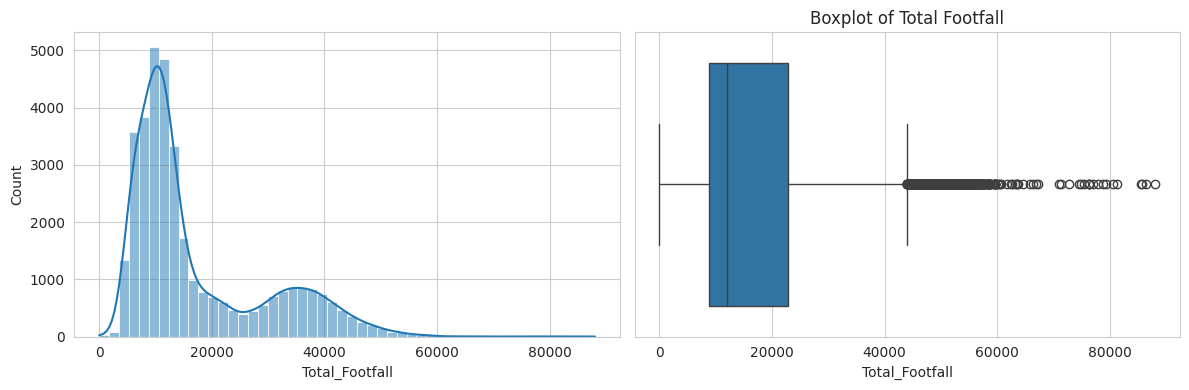

Skewness: 1.24


In [21]:
plt.figure(figsize = (12,4))

plt.subplot(1,2,1)
sns.histplot(df['Total_Footfall'], bins = 50,kde = True)

plt.subplot(1,2,2)
sns.boxplot(x = df['Total_Footfall'])
plt.title("Boxplot of Total Footfall")

plt.tight_layout()
plt.show()

print("Skewness:", round(df["Total_Footfall"].skew(), 2))

The distribution is right-skewed (skewness 1.24). The mean (about 17,200) sits well above the median (about 12,000), so a typical station-day is closer to 12,000 riders, and a minority of very busy records pulls the average up. The histogram also has two humps: a large one around 6,000–15,000 (regular stations) and a smaller one around 29,000–41,000 (interchange and market hubs), with a dip around 23,000 between them. 

The boxplot flags about 1,260 records (3.5%) above roughly 44,000 as outliers. All of them are interchange or commercial/leisure stations, so they are real peak days at the busiest hubs, not errors, and should not be removed. The maximum is about 88,000.

#### Numeric columns distributions 

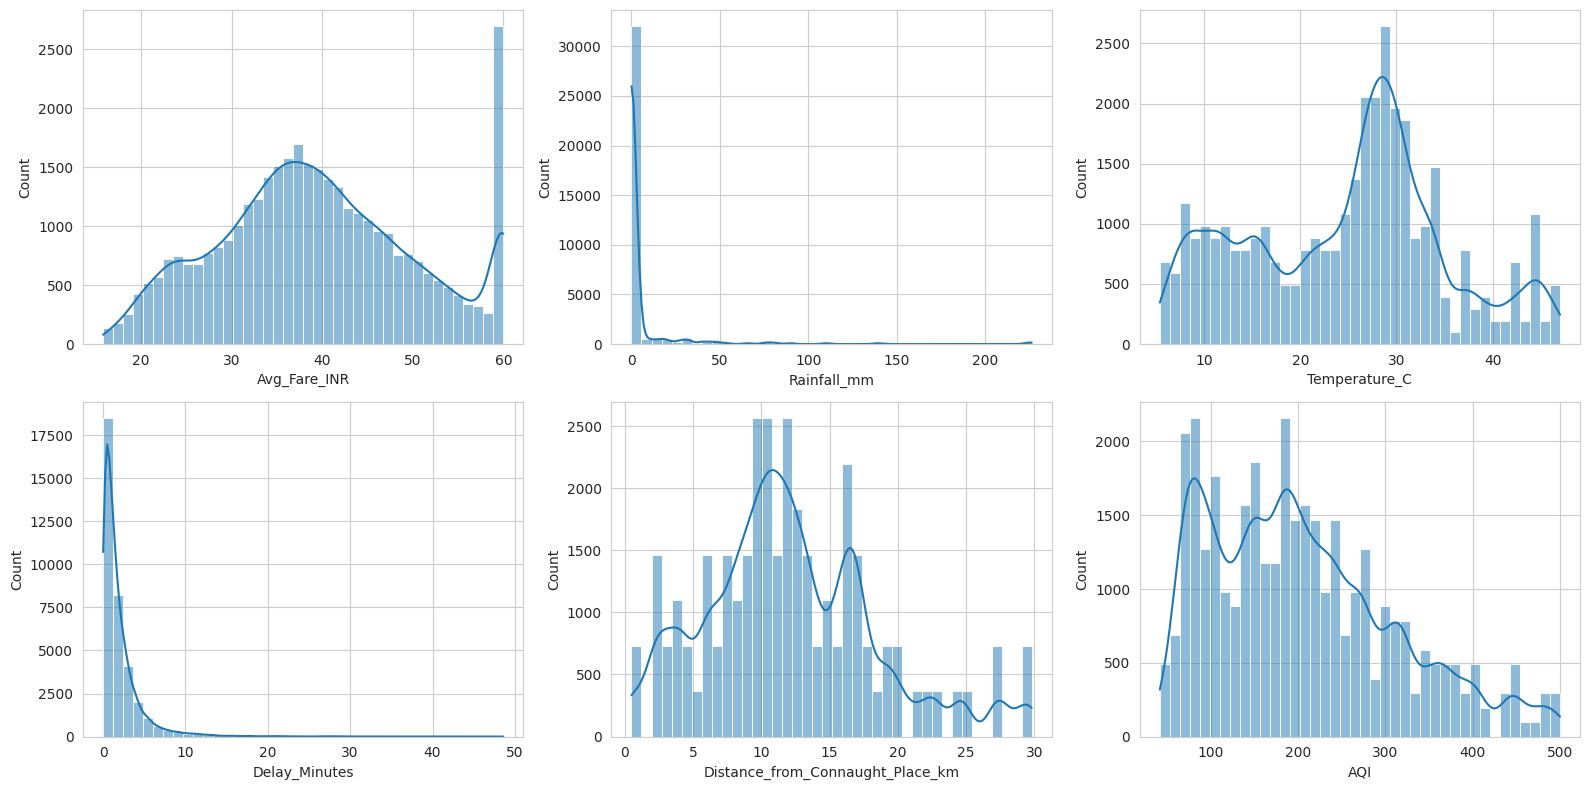

In [22]:
num_cols = ["Avg_Fare_INR", "Rainfall_mm", "Temperature_C",
            "Delay_Minutes", "Distance_from_Connaught_Place_km",'AQI']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flatten(), num_cols):
    sns.histplot(df[col], bins=40, kde=True, ax=ax)
plt.tight_layout()
plt.show()

Avg_Fare_INR: roughly symmetric (skew 0.18), centered around ₹39, with a small pile-up at the ₹60 cap (~7% of records).

Temperature_C: spread from 5°C to 47°C with several humps, because it reflects the seasons. The tallest bin is around 26–30°C, and there is a small tail of heatwave days above 40°C.

Delay_Minutes: the most skewed column (skew 5.1). The median is only 1.2 min, but the maximum is about 49 min. Only ~2% of records exceed 10 minutes, and those are mostly signal-failure and heavy-rain days, so don’t treat them as errors.

Distance_from_Connaught_Place_km: mildly right-skewed (median ~11 km); a few outer stations stretch the tail to about 30 km.

AQI (if you plot it): right-skewed with a median of ~189. About 19% of records are above 300 (Very Poor/Severe), mostly Nov–Jan.

Rainfall_mm (if you plot it): 82% of records are exactly 0, so it is a huge spike at zero with a long tail up to ~226 mm. Plot it only for rainy days or on a log scale

<Axes: xlabel='Peak_Hour_Footfall_Pct', ylabel='Count'>

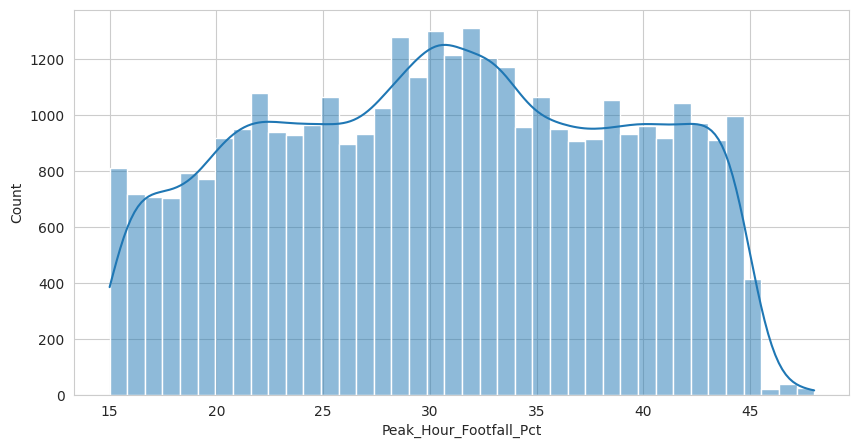

In [23]:
sns.histplot(df['Peak_Hour_Footfall_Pct'],bins=40, kde=True)

 Broad and fairly flat from 15% to 48% (mean ~31%). The low end is mostly weekends/holidays and the high end is weekday commuters.

#### Categorical Columns Distribution

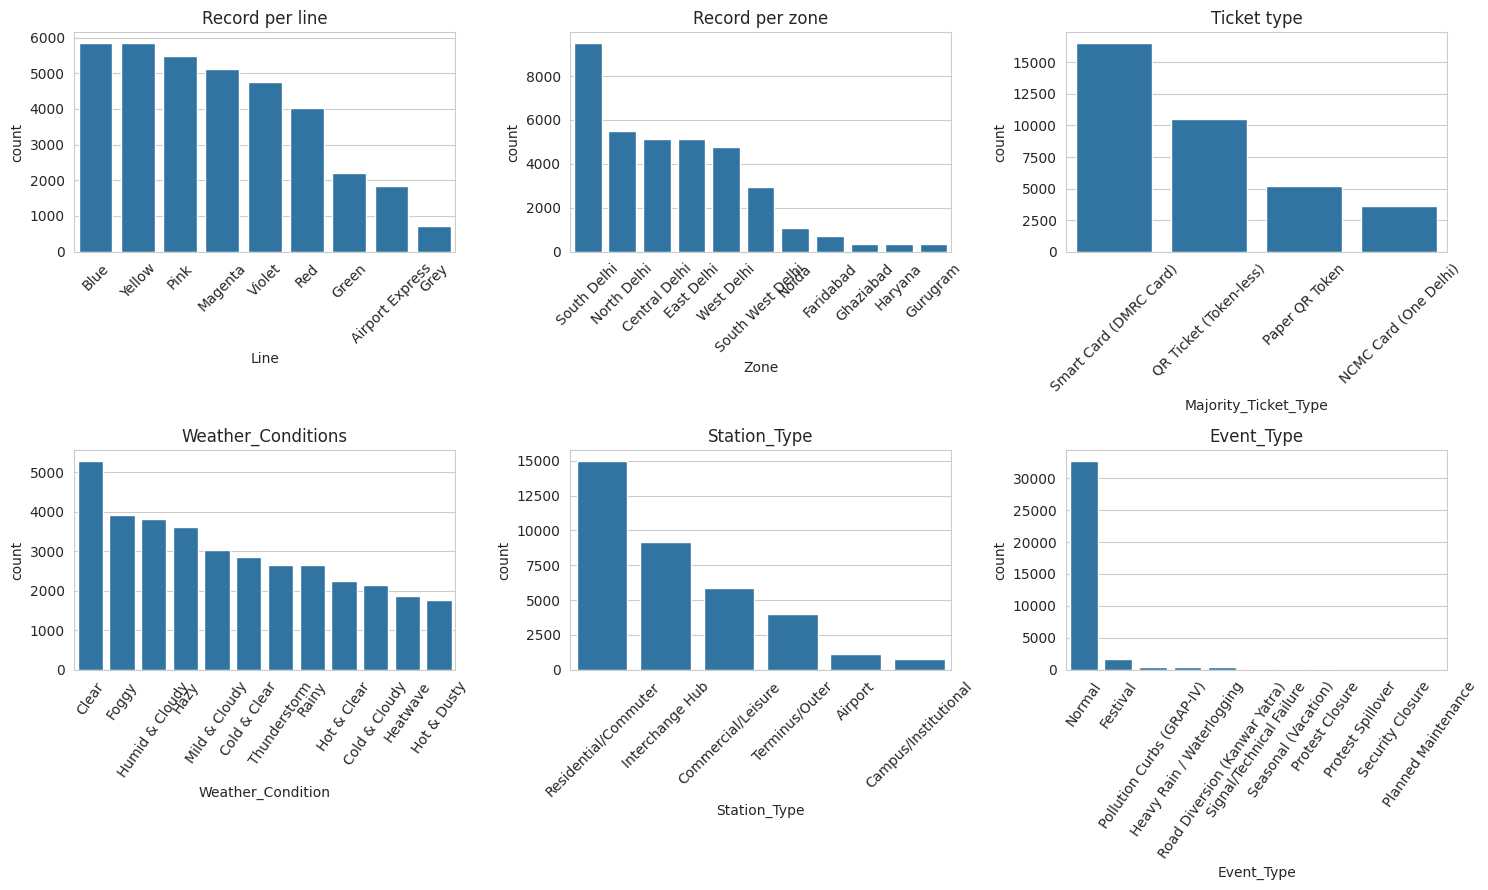

In [24]:
fig, axes = plt.subplots(2,3, figsize =(15,9))

sns.countplot(data = df, x ='Line', order = df['Line'].value_counts().index, ax = axes[0,0])
axes[0,0].set_title('Record per line')
axes[0,0].tick_params(axis = 'x', rotation = 45)

sns.countplot(data = df, x = 'Zone', order = df['Zone'].value_counts().index,ax = axes[0,1])
axes[0,1].set_title('Record per zone')
axes[0,1].tick_params(axis = 'x', rotation = 45)

sns.countplot(data = df, x = 'Majority_Ticket_Type', order = df['Majority_Ticket_Type'].value_counts().index,ax = axes[0,2])
axes[0,2].set_title('Ticket type')
axes[0,2].tick_params(axis = 'x', rotation = 45)

sns.countplot(data = df, x = 'Weather_Condition', order = df['Weather_Condition'].value_counts().index, ax = axes[1,0])
ax = axes[1,0].set_title('Weather_Conditions')
ax = axes[1,0].tick_params(axis = 'x', rotation = 55)

sns.countplot(data = df, x = 'Station_Type', order = df['Station_Type'].value_counts().index,ax = axes[1,1])
ax = axes[1,1].set_title('Station_Type')
ax = axes[1,1].tick_params(axis = 'x', rotation = 45)

sns.countplot(data = df, x = 'Event_Type', order = df['Event_Type'].value_counts().index,ax = axes[1,2])
ax = axes[1,2].set_title('Event_Type')
ax = axes[1,2].tick_params(axis = 'x', rotation = 55)

plt.tight_layout()
plt.show()

Line: Blue and Yellow lead with 5,856 records each, and Grey has only 732. The counts reflect how many stations each line has, not ridership, so don’t read them as line popularity.

Zone: South Delhi dominates (9,516 records, about 27%), while Ghaziabad, Gurugram and Haryana have only 366 each (one station apiece). Per-zone averages for those are based on a single station.

Station_Type: Residential/Commuter is the largest group (15,006), and Campus (732) and Airport (1,098) are tiny. Be careful drawing conclusions from the small groups.

Majority_Ticket_Type: Smart Card is the largest (46%), followed by QR (29%), Paper QR (15%) and NCMC (10%).

Weather (counted in days): all 12 conditions appear, with Clear the most common (54 days). Heatwave (19 days) and Hot & Dusty (18 days) are the rarest. Count weather per day, not per row, or each day gets repeated 98 times.

Event_Type: 91% of records are Normal. Festival is the largest event category (1,602), and the closure types are tiny (Protest Closure 28, Security Closure 8, Planned Maintenance 4).

#### Outlier detection using IQR on Total_Footfall

In [25]:
Q1 = df["Total_Footfall"].quantile(0.25)
Q3 = df["Total_Footfall"].quantile(0.75)
IQR = Q3 - Q1
LF = Q1 - 1.5*IQR
UF = Q3 + 1.5*IQR

outliers = df[(df["Total_Footfall"] < LF) | (df["Total_Footfall"] > UF)]
print(f"IQR bounds: {LF:.0f} to {UF:.0f}")
print("Number of outliers:", len(outliers))
print(outliers["Station_Name"].value_counts().head(10))

IQR bounds: -12248 to 44012
Number of outliers: 1263
Station_Name
Rajiv Chowk            371
Lajpat Nagar           280
Hauz Khas              266
New Delhi               72
Central Secretariat     30
Kashmere Gate           30
Mandi House             28
Yamuna Bank             24
Mayur Vihar-I           22
Rajouri Garden          21
Name: count, dtype: int64


## Anomalies and events
Each record vs. that station's own baseline

In [26]:
df["station_median"] = df.groupby(["Station_Name","Line"])["Total_Footfall"].transform("median")
df["ratio_to_normal"] = df["Total_Footfall"] / df["station_median"]

closures = df[df["ratio_to_normal"] < 0.05]
print(closures[["Date","Station_Name","Event_Type","Total_Footfall"]])

            Date         Station_Name                 Event_Type  \
4236  2024-02-13     Bahadurgarh City            Protest Closure   
4334  2024-02-14     Bahadurgarh City            Protest Closure   
6702  2024-03-09                Palam        Planned Maintenance   
6800  2024-03-10                Palam        Planned Maintenance   
17565 2024-06-28               Mundka  Heavy Rain / Waterlogging   
18633 2024-07-09          Mandi House            Protest Closure   
18637 2024-07-09          Rajiv Chowk            Protest Closure   
18704 2024-07-09  Central Secretariat            Protest Closure   
18714 2024-07-09          Rajiv Chowk            Protest Closure   
18731 2024-07-10          Mandi House            Protest Closure   
18735 2024-07-10          Rajiv Chowk            Protest Closure   
18802 2024-07-10  Central Secretariat            Protest Closure   
18812 2024-07-10          Rajiv Chowk            Protest Closure   
18942 2024-07-12            Najafgarh  Heavy Rai

Closure detection (ratio to normal): on normal days the ratio sits at about 1.0 (middle 50% between 0.89 and 1.10). Exactly 19 records fall below 0.05, and they are all the Closed stations: CP protest (Rajiv Chowk, Mandi House, Central Secretariat), Bahadurgarh City, four waterlogged stations, Lal Quila on Independence Day, and two planned-maintenance stations (Palam, Kalindi Kunj). The ratio catches them cleanly, where the IQR rule caught none.

####  Impact of each event type vs normal days

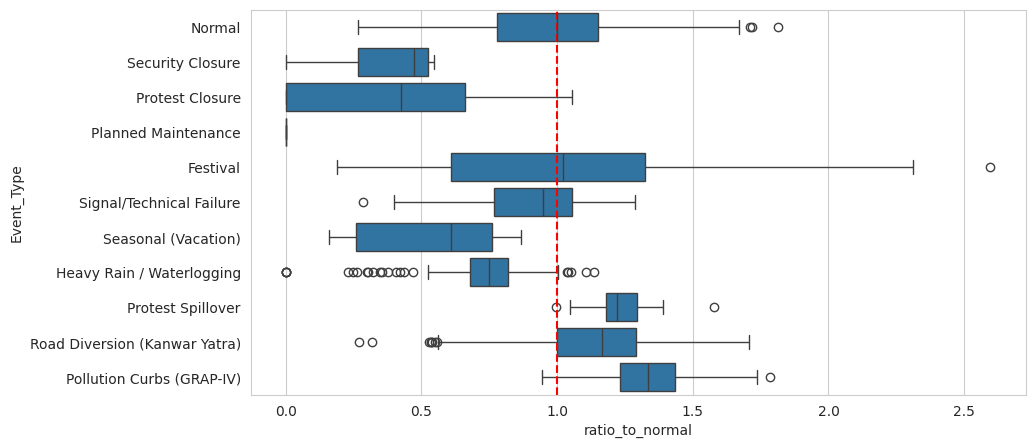

In [27]:
sns.boxplot(data=df, y="Event_Type", x="ratio_to_normal")
plt.axvline(1, color="red", ls="--")

Graph: footfall ratio (vs normal) by event type. 1.0 is normal, below 1 means the event cut ridership, above 1 means it raised it. I used a month-adjusted baseline here, which is cleaner than the year-wide one.

Biggest drops: Planned Maintenance goes to 0, and Protest Closure (median 0.45, with the closed stations at 0) and Security Closure (0.47) roughly halve footfall. Because Protest Closure mixes closed and partially open stations, its box is very wide (0 to 0.69).

Moderate drops: Summer Vacation at campus stations is about 0.67, Heavy Rain about 0.75, and Signal Failure about 0.83, which is a mild loss of riders but a huge delay (about 26 min).

Festival looks “normal” (0.93), but that’s misleading. Its box is very wide (0.53 to 1.09) because it mixes Holi and Diwali day (network down) with the shopping rush at market stations (up to 2.6x). Break it down by Event_Name before concluding anything.

Increases: Kanwar Yatra is about 1.22 and Protest Spillover is about 1.30, so displaced riders show up at neighbouring stations. GRAP-IV is only 1.05 here. The 1.22 from the year-wide baseline was mostly the November demand peak, not the pollution curbs.

Normal days: the box is tight around 1.0 (0.92–1.07), so anything outside it really is an event effect.

## Bivariate analysis

#### Footfall by Line

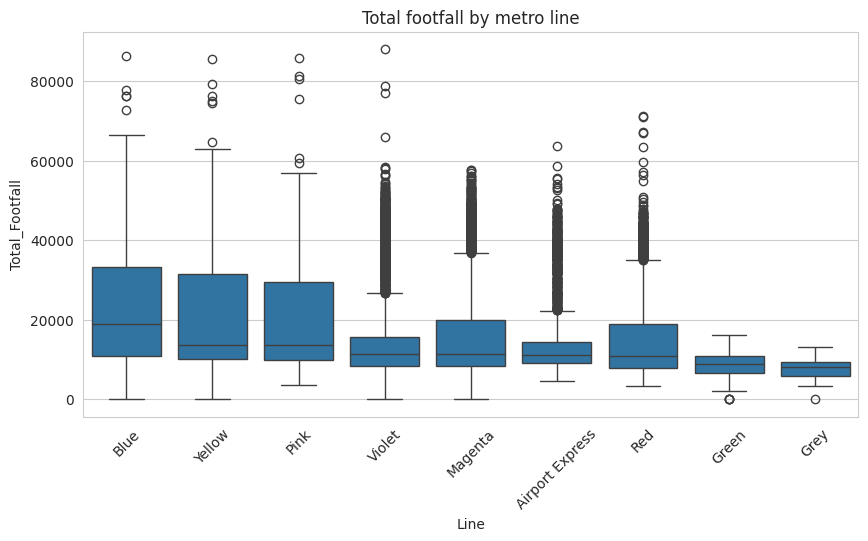

In [28]:
plt.figure(figsize = (10,5))

order = df.groupby('Line')['Total_Footfall'].median().sort_values(ascending = False).index
sns.boxplot(data = df, x = 'Line', y = 'Total_Footfall', order = order)
plt.title('Total footfall by metro line')
plt.xticks(rotation = 45)
plt.show()

Blue leads with a median of about 19,000 riders per station-day, followed by Yellow (13,700) and Pink (13,500). Together, Blue, Yellow and Pink carry about 57% of all footfall.

Green and Grey are the lowest (medians ~9,000 and ~8,200) and together carry about 4%. Their boxes are narrow and their maximums are low (Green tops out near 16,000), because they have no interchange stations.

Box width tracks interchange share. Blue (56% interchange stations), Yellow and Pink have wide boxes (roughly 10,000 to 33,000), since each mixes busy hubs and quiet stops. Lines with few hubs are tight.

Caveat: Airport Express looks mid-pack (median ~11,000) because the generator treats its stations like regular ones. A real Airport Express would behave differently, so call this a limitation of the synthetic data.

#### Footfall: Interchange vs Non-Interchange

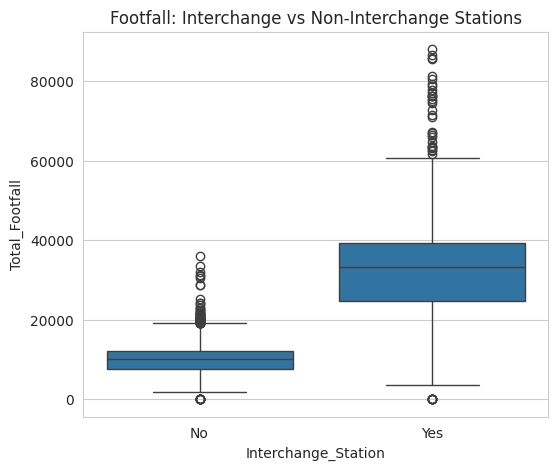

Interchange_Station
No     10045.0
Yes    33317.0
Name: Total_Footfall, dtype: float64


In [29]:
plt.figure(figsize=(6,5))
sns.boxplot(data=df, x="Interchange_Station", y="Total_Footfall")
plt.title("Footfall: Interchange vs Non-Interchange Stations")
plt.show()

print(df.groupby("Interchange_Station")["Total_Footfall"].median())

Interchange stations were generated with roughly 3.3x the base footfall of regular stations (33,000 vs 10,000 baseline).

Only 32% of records are interchange stations, yet they generate about 60% of all footfall.

Insight: being an interchange is the single strongest predictor of a station's footfall — bigger than line, weather, or day of week.

#### Footfall: Weekday vs Weekend

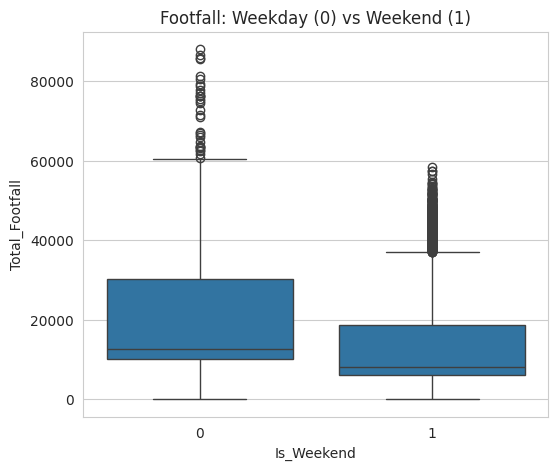

Is_Weekend
0    18891.459339
1    12885.679553
Name: Total_Footfall, dtype: float64


In [30]:
plt.figure(figsize = (6,5))
sns.boxplot(data = df, x = 'Is_Weekend',y = 'Total_Footfall')
plt.title("Footfall: Weekday (0) vs Weekend (1)")
plt.show()

print(df.groupby('Is_Weekend')['Total_Footfall'].mean())

Weekend footfall multiplier was 0.55–0.7x, weekday was 0.95–1.15x. 

Insight: ridership drops by roughly 35–45% on weekends, confirming this is dominated by office/commute traffic rather than leisure travel.

#### Footfall by Weather Condition 

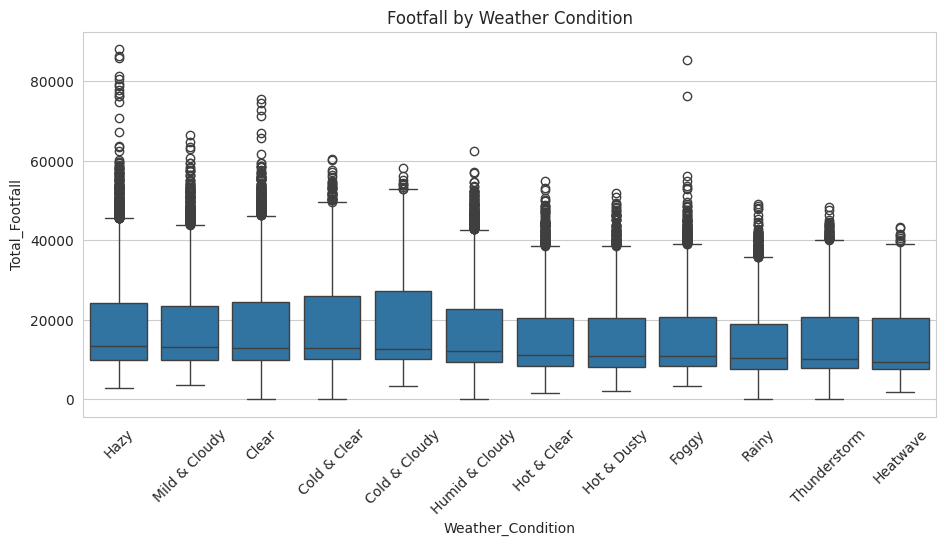

In [31]:
plt.figure(figsize=(11,5))
order = df.groupby("Weather_Condition")["Total_Footfall"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="Weather_Condition", y="Total_Footfall", order=order)
plt.title("Footfall by Weather Condition")
plt.xticks(rotation=45)
plt.show()

Raw medians: Hazy, Mild & Cloudy and Clear sit highest (13,000-13,500), while Heatwave (9,500), Thunderstorm (10,000), Rainy (10,300) and Foggy (~10,800) are lowest.

Compared within the same month, only four conditions have a real effect. Heatwave, Thunderstorm, Rainy and Foggy each run about 15% below good-weather days, and every other condition (including Hot & Clear and Hot & Dusty) shows no effect.

Weather is a secondary driver. A 15% dip is small next to interchange status (3.3x) or closures (near zero).

#### Fare vs Distance from city center (expect strong positive relationship

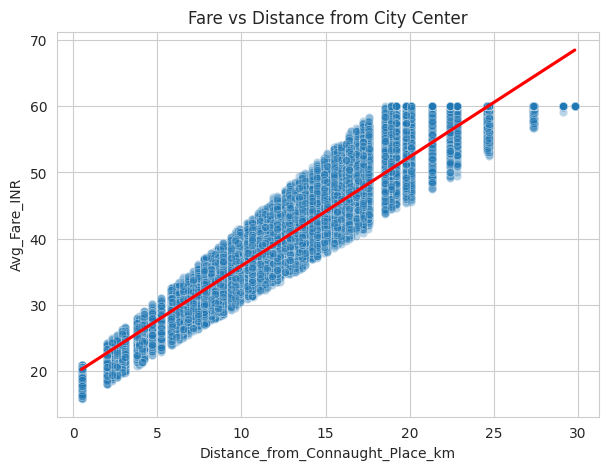

Correlation: 0.96


In [32]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x="Distance_from_Connaught_Place_km", y="Avg_Fare_INR", alpha=0.3)
sns.regplot(data=df, x="Distance_from_Connaught_Place_km", y="Avg_Fare_INR",
            scatter=False, color="red")
plt.title("Fare vs Distance from City Center")
plt.show()

print("Correlation:", df["Distance_from_Connaught_Place_km"].corr(df["Avg_Fare_INR"]).round(2))

Fare was built directly from distance (15–20 base + distance × 1.5–2.2, capped at ₹60). Insight: this should show a strong, almost linear positive correlation (likely r ≈ 0.85–0.95) — confirms Delhi Metro's real-world distance-based fare structure, and it's a good "sanity check" plot to show your fare logic makes sense.

#### Monthly trend


<Axes: title={'center': 'Median Footfall by Month'}, xlabel='Month'>

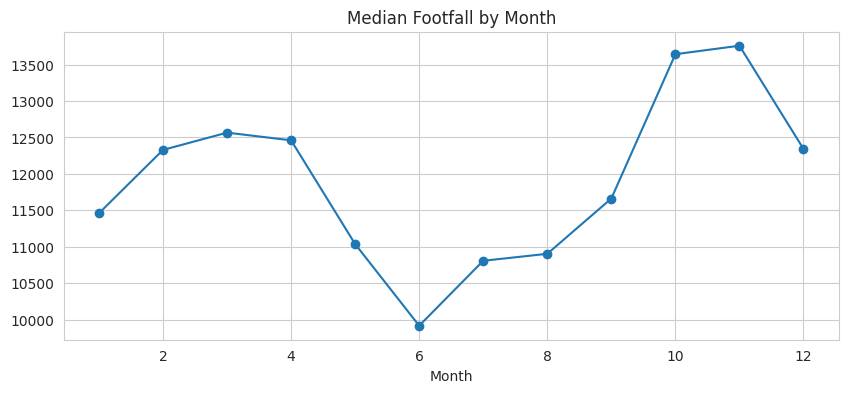

In [33]:
df["Month"] = df["Date"].dt.month
monthly = df.groupby("Month")["Total_Footfall"].median()
monthly.plot(marker="o", figsize=(10,4), title="Median Footfall by Month")

Lowest in June (median 9,900), then July (10,800) and August (10,900): the summer-vacation, heat and monsoon slump.

Highest in November and October (13,800 and 13,600), driven by the festive season (Dussehra, Diwali, Chhath) and a rising ridership trend over the year.

The pattern holds on weekdays only and on normal days only, so it isn’t caused by weekends or event spikes. The gap between the best and worst month is about 40% (June to November).

#### Daily network total with a 7-day rolling average


<Axes: xlabel='Date'>

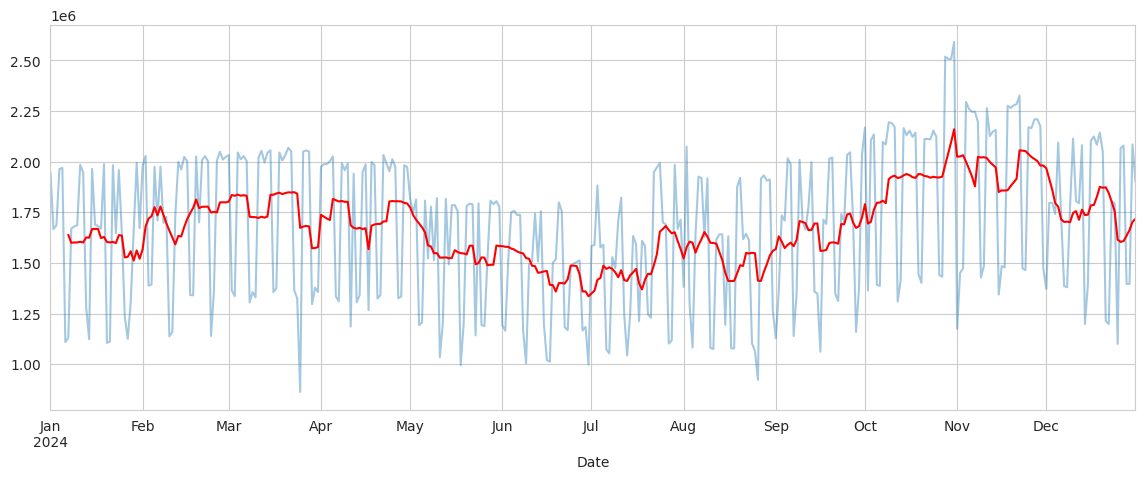

In [34]:
daily = df.groupby("Date")["Total_Footfall"].sum()
ax = daily.plot(alpha=0.4, figsize=(14,5))
daily.rolling(7).mean().plot(ax=ax, color="red", label="7-day avg")

A weekly sawtooth dominates the raw line. Weekdays average about 1.85M riders and weekends about 1.26M, roughly 32% lower. The 7-day average smooths this out so the real trends are visible.

The trend: the 7-day average bottoms out around 30 June (1.34M, the summer trough), climbs through the monsoon, and peaks on 31 October (2.16M). Across the year there is also a slow upward drift (January average 1.62M, December 1.74M).

Biggest spikes: 28-31 October, the Dhanteras and Diwali shopping rush, with 31 October the busiest day (2.59M, about 54% above the daily average). Chhath (4 Nov) and the GRAP-IV days (22 Nov) are also high.

Biggest dips: Holi (25 Mar, ~0.86M, the lowest day), Janmashtami (26 Aug), and several weekend days in May-June, which are the summer-vacation lows.

#### Festival day effect

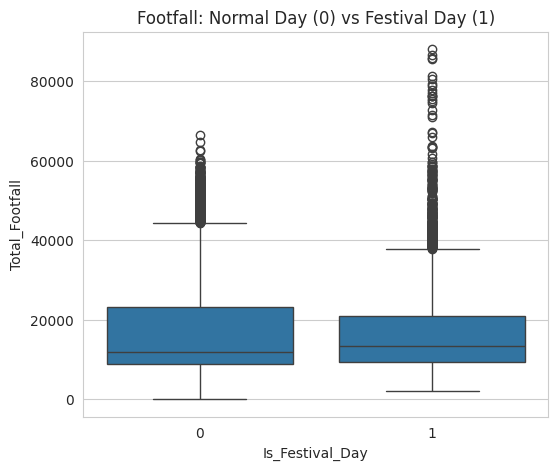

In [35]:
plt.figure(figsize=(6,5))
sns.boxplot(data=df, x="Is_Festival_Day", y="Total_Footfall")
plt.title("Footfall: Normal Day (0) vs Festival Day (1)")
plt.show()

Directly reflects the 1.3–1.8x multiplier applied on ~3% of days. Insight: festival/event days cause a sharp, visible rightward shift in the distribution — useful for arguing that special-event planning (extra trains, staffing) is data-justified.

## Multivariate analysis

#### Correlation heatmap

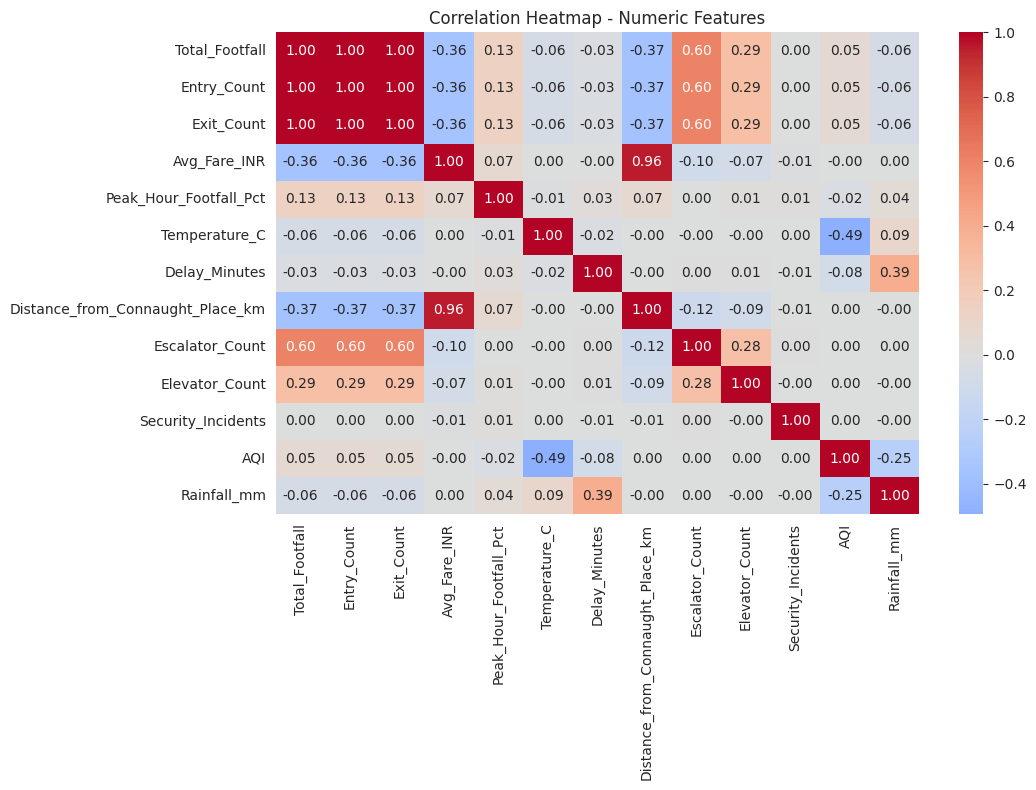

In [36]:
num_cols = ['Total_Footfall','Entry_Count','Exit_Count','Avg_Fare_INR','Peak_Hour_Footfall_Pct',
            'Temperature_C','Delay_Minutes','Distance_from_Connaught_Place_km',
            'Escalator_Count','Elevator_Count','Security_Incidents','AQI','Rainfall_mm']

plt.figure(figsize=(11,8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap - Numeric Features")
plt.tight_layout()
plt.show()

Entry_Count and Exit_Count correlate ~1.00 with Total_Footfall. They are its components, so drop them from any modelling.

Fare vs Distance is 0.96: fare is almost fully determined by distance. This also explains why Fare (-0.36) and Distance (-0.37) both correlate negatively with footfall: outer stations are quieter, and fare just echoes distance.

Platforms (0.82), Escalators (0.60) and Elevators (0.29) track footfall. They are proxies for station size and interchange status, not causes of ridership.

Weekend (-0.22) and Holiday (-0.10) are weaker than expected because market stations barely drop on weekends. Weekend correlates strongly with Peak_Hour_Footfall_Pct (-0.69): weekends flatten the rush-hour share.

Temperature, Rainfall, AQI, Delay and Security are all near zero with footfall (|r| ≤ 0.06). That doesn’t mean no effect: station size varies so much that it swamps a ~15% weather dip. Test those within a station or with the baseline ratio.

Other relationships worth noting: Rainfall vs Delay is +0.40 (rain disrupts service), and Temperature vs AQI is -0.49 (cold months are the polluted ones).

#### Footfall by Line x Weekend (pivot heatmap)


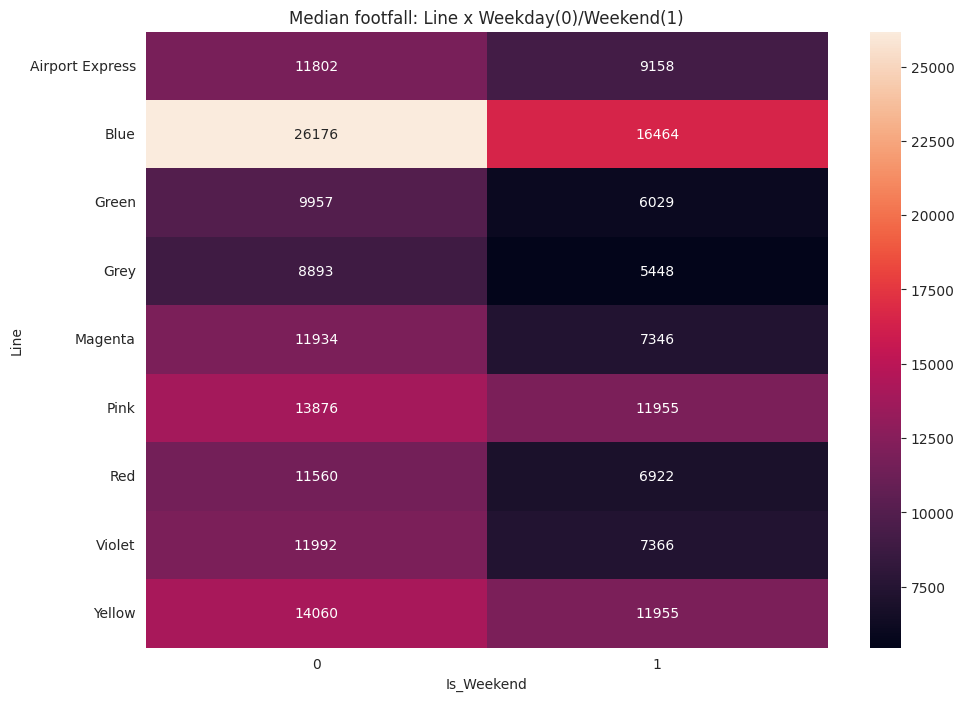

In [37]:
pt = df.pivot_table(values="Total_Footfall", index="Line", columns="Is_Weekend", aggfunc="median")

plt.figure(figsize = (11,8))
sns.heatmap(pt, annot = True, fmt = '.0f')
plt.title('Median footfall: Line x Weekday(0)/Weekend(1)')
plt.show()

Blue Line towers over every other line on weekdays — more than double the next-highest line. This is driven by its high concentration of interchange stations (Rajiv Chowk, Kirti Nagar, Janakpuri West, Mandi House).

Every single line drops on weekends, but Blue drops hardest in absolute terms (a ~41% fall) while still remaining the busiest line even on weekends.

#### Season x Station_Type

<Axes: xlabel='Season', ylabel='Station_Type'>

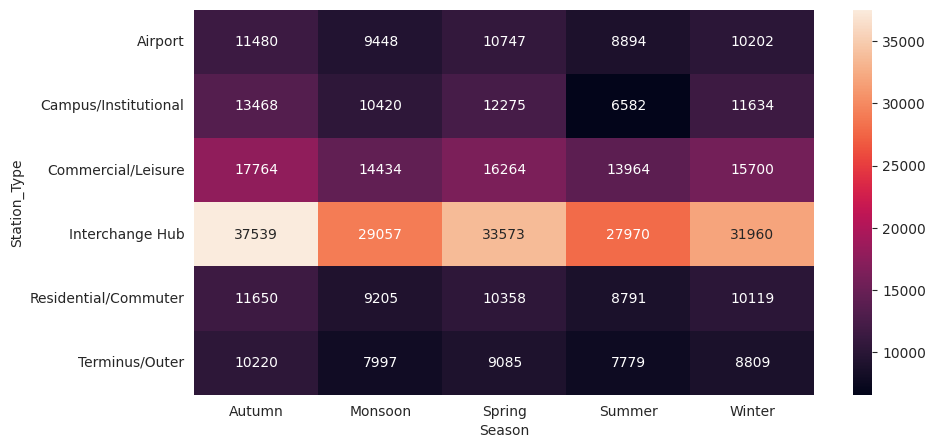

In [38]:
sns.heatmap(df.pivot_table(values="Total_Footfall", index="Station_Type",
            columns="Season", aggfunc="median"), annot=True, fmt=".0f")

Interchange Hubs are the busiest in every season (about 28,000-37,500), with Commercial/Leisure next. Terminus/Outer and Residential stations are the quietest.

Autumn is the peak and Summer the trough for almost every type. Most types drop about 21-25% from Autumn to Summer, and Interchange Hubs swing the most in absolute terms (about 37,500 to 28,000).

Campus stations are the exception. They fall about 51% in Summer (median ~6,600, versus ~13,500 in Autumn). They are the only type where the summer drop is much bigger than the network-wide dip, which comes from the vacation closures of schools and colleges.

Campus stations are also busy in Spring and Autumn (relative index 1.13 and 1.24), so they are the most seasonal type.

Monsoon sits between Summer and Winter for every type, a mild dip of about 8-9% below each type’s average.

#### Weekend effect by station type 

<Axes: xlabel='Station_Type', ylabel='Total_Footfall'>

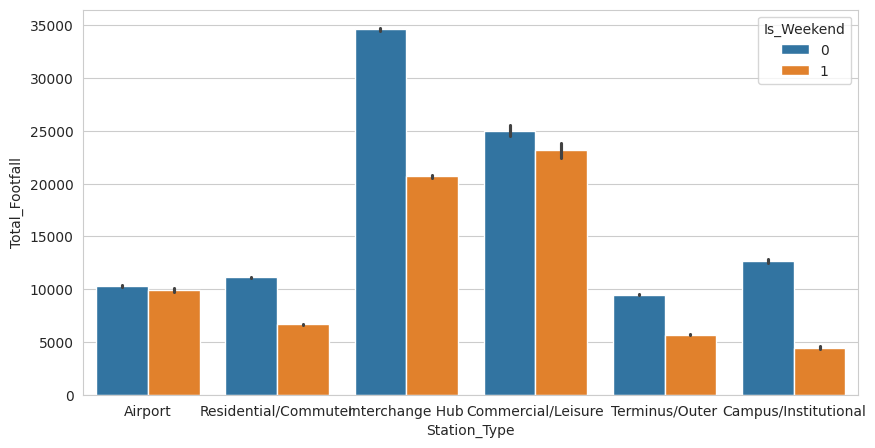

In [39]:

normal = df[(df.Event_Type=="Normal") & (df.Is_Public_Holiday==0)]
sns.barplot(data=normal, x="Station_Type", y="Total_Footfall", hue="Is_Weekend")


#### Interchange x Weekend interaction

<function matplotlib.pyplot.show(close=None, block=None)>

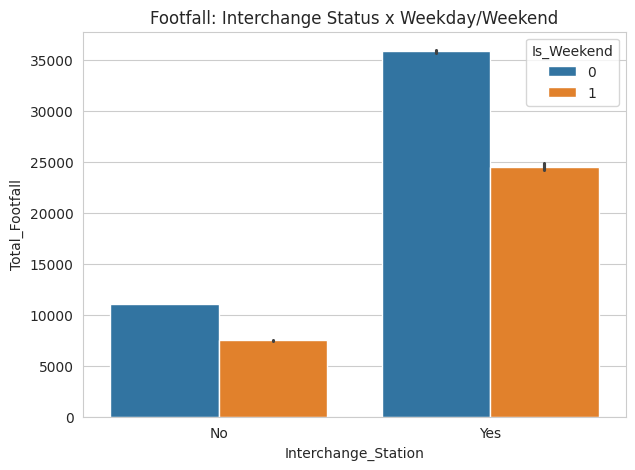

In [40]:
plt.figure(figsize = (7,5))
sns.barplot(data = df, x = 'Interchange_Station', y = 'Total_Footfall', hue = 'Is_Weekend')
plt.title('Footfall: Interchange Status x Weekday/Weekend')
plt.show

Interchange stations see a 41% weekday-to-weekend drop; non-interchange stations drop slightly less in percentage terms (40%) — the weekend effect is proportionally similar across both groups, meaning it's not just an interchange phenomenon — it's a network-wide commuter pattern.

#### AQI vs footfall

<Axes: xlabel='AQI', ylabel='Total_Footfall'>

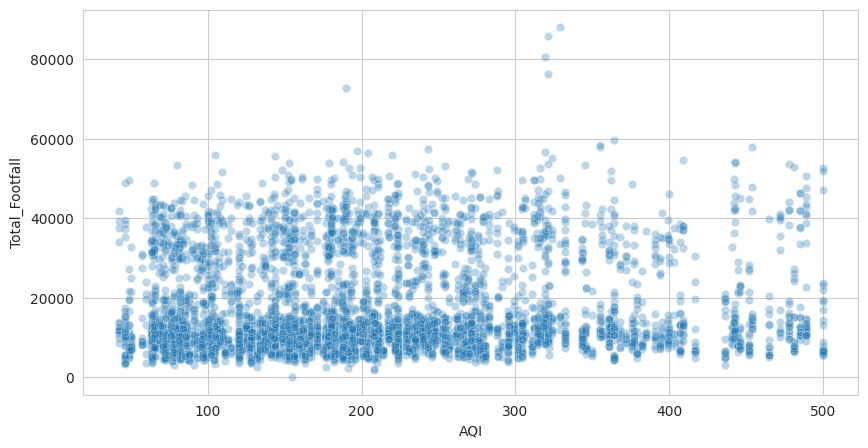

In [41]:
sns.scatterplot(data=df.sample(5000), x="AQI", y="Total_Footfall", alpha=0.3)

The raw scatter looks like a weak positive trend (r = 0.06), and the median footfall climbs from about 10,600 on “Good” air days to about 13,000 on “Severe” days. That would suggest more riders on polluted days, but it is not a real effect.

It is a seasonal confounder. AQI is highest in November-January, when ridership is also high (festive season), and lowest in the monsoon, when ridership is low. Comparing within the same month, the ratio is flat at 1.00 across all AQI categories, and the correlation drops to about -0.03.

The one direct pollution effect is the GRAP-IV period (22 Nov), a small bump of about 5% from curbs on road vehicles, not from the AQI value itself.

#### Pairplot for a quick multivariate scan

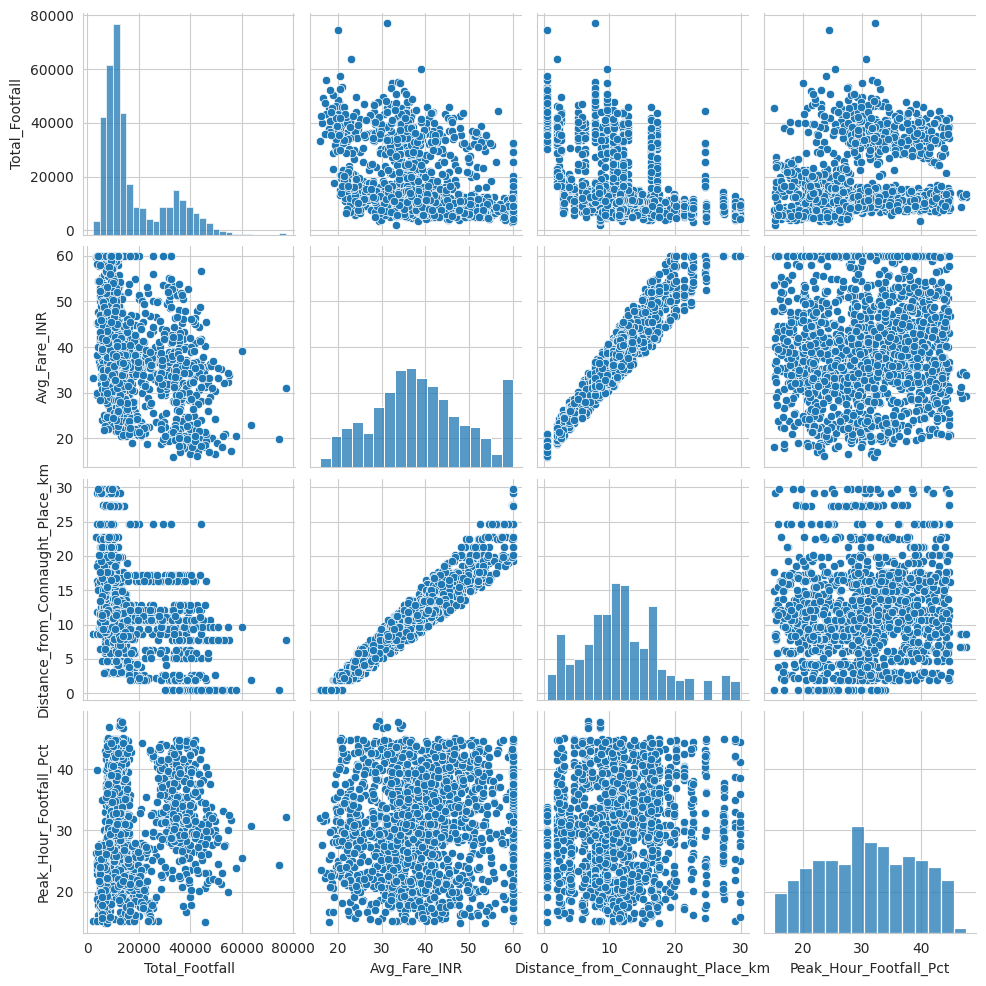

In [42]:
sns.pairplot(df[["Total_Footfall","Avg_Fare_INR","Distance_from_Connaught_Place_km","Peak_Hour_Footfall_Pct"]].sample(1500, random_state=1))
plt.show()

## Feature Engineering

In [43]:
# Footfall per platform
df['Footfall_per_platform'] = (df['Total_Footfall']/df['Number_of_Platforms']).round(0)

In [44]:
# Entry/Exit ratio
df['Entry_exit_ratio'] = (df["Entry_Count"] / df["Exit_Count"]).round(3)

In [45]:
# Rush hour absolute footfall
df["Peak_Hour_Footfall_Count"] = (df["Total_Footfall"] * df["Peak_Hour_Footfall_Pct"] / 100).round(0)

In [46]:
df['Distance_Band'] = pd.cut(df['Distance_from_Connaught_Place_km'],bins = [0,5,10,15,20,35],labels = ['0-5km','5-10km','10-15km','15-20km','20+km'])

In [47]:
df["Amenity_Score"] = (
    df["Escalator_Count"] +
    df["Elevator_Count"] * 2 +  
    df["Parking_Available"].map({"Yes": 3, "No": 0, "Unknown": 0}) +
    df["Feeder_Bus_Available"].map({"Yes": 2, "No": 0})
)

In [48]:
df[['Peak_Hour_Footfall_Count','Entry_exit_ratio','Footfall_per_platform','Amenity_Score','Distance_Band']].head()

,Peak_Hour_Footfall_Count,Entry_exit_ratio,Footfall_per_platform,Amenity_Score,Distance_Band
0,3153.0,1.001,5381.0,13,10-15km
1,4199.0,0.980,6582.0,8,5-10km
2,3911.0,1.038,5462.0,6,15-20km
3,15348.0,1.009,8944.0,9,0-5km
4,5260.0,0.983,7205.0,2,0-5km


## Summary of Findings — Delhi Metro Ridership EDA 

**Dataset:** 35,868 station-day records (after removing 25 duplicates) across 88 stations
(98 station–line combinations) and 9 lines, covering all 366 days of 2024. 37 columns.

### Key Findings
1. **Footfall is right-skewed and has two tiers.** The mean (17,200) is well above the
   median (12,000), with a second hump of busy hubs (29,000–41,000). The 1,260 high
   outliers (3.5%) are all interchange/commercial hubs, so they are genuine peak days, not errors.

2. **Interchange status is the strongest single driver.** Interchange stations have a median
   of 33,300 riders/day versus 10,000 at regular stations (about 3.3x). They are 32% of
   records but generate 60% of all footfall, and the gap holds on weekdays and weekends.

3. **Line ranking mostly reflects interchange mix.** Blue (median ~19,000), Yellow and Pink
   carry 57% of footfall; Green and Grey are lowest. Among non-interchange stations, all
   lines fall within roughly 8,200–11,000.

4. **Clear seasonal cycle.** The median footfall is lowest in June (9,900: heat, summer
   vacation) and highest in October–November (13,600–13,800: festive season), a 40% swing.
   Network-wide, that is 1.4M riders/day in June versus 2.0M in October. Campus stations
   are the most seasonal, dropping 51% in summer.

5. **Weekly rhythm and festivals.** Weekday network totals average 1.85M versus 1.26M on
   weekends (32% lower). Commuter stations drop 40% on weekends, while market/leisure stations
   barely drop. The lowest day is Holi (0.86M) and the busiest is 31 Oct, during the Diwali
   shopping rush (2.59M, 54% above average).

6. **Weather has a modest effect.** Only heatwave, thunderstorm, rain and fog reduce
   footfall, by 15% versus good-weather days in the same month. Raw weather comparisons
   exaggerate this, because heatwaves fall in low-demand months.

7. **AQI has no independent effect.** The raw trend (more riders on polluted days) comes from
   both rising in the same season (Nov–Jan). Within the same month the ratio is flat.

8. **Disruptions are rare but have the strongest signals.** Only ~9% of records are event
   days, yet:
   - Closures cut footfall to near zero (19 records), which the IQR rule missed. A per-station
     baseline ratio caught all of them.
   - The July CP protest: Rajiv Chowk fell from ~36,000 to 16 and 24 riders on the two closure
     days, then recovered to ~29,000 on reopening. Nearby stations (e.g. New Delhi) gained riders.
   - Event impact on a month-adjusted baseline: protest/security closures ~0.45, vacation ~0.67,
     heavy rain ~0.75, signal failure ~0.83 (but delays jump from ~1 to ~26 minutes),
     Kanwar Yatra ~1.22, protest spillover ~1.30.

9. **Correlations.** Fare and distance correlate at 0.96; platforms (0.82) and escalators (0.60)
   track footfall as proxies for station size. Weather, AQI, delay and security show near-zero
   correlation with footfall because station size swamps them.

### Limitations
- The dataset is **synthetic**, and all events (protests, closures, rain days) are
  simulated, so it shows techniques, not real DMRC accuracy.
- One year of data cannot teach a model about a second Diwali or year-on-year growth.
- Peripheral zones (Ghaziabad, Gurugram, Haryana) each contain one station, so zone-level
  results there rest on a single station.
- Airport Express looks mid-pack only because the generator treats its stations like regular ones.
- Event inputs are only known in advance for scheduled events; unplanned ones need live data.